In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(sklearn.__version__)

1.9.1


In [2]:
df=pd.read_csv("data/application.csv")

In [3]:
df.shape

(307511, 122)

In [4]:
df['TARGET'].value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

In [5]:
df.dtypes.value_counts()

float64    65
int64      41
str        16
Name: count, dtype: int64

In [6]:
missing = df.isna().mean().sort_values(ascending=False)
missing.head(10)

COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
dtype: float64

In [7]:
df['SK_ID_CURR'].is_unique

True

In [8]:
df.groupby('CODE_GENDER')['TARGET'].mean()

CODE_GENDER
F      0.069993
M      0.101419
XNA    0.000000
Name: TARGET, dtype: float64

In [9]:
(df['DAYS_EMPLOYED'] == 365243).mean()

np.float64(0.18007160719453938)

In [10]:
import numpy as np

In [11]:
(df['DAYS_EMPLOYED'] ==np.nan).mean()

np.float64(0.0)

In [12]:
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
df['DAYS_EMPLOYED'].isna().mean()

np.float64(0.18007160719453938)

In [13]:
df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365
df['AGE_YEARS'].min(), df['AGE_YEARS'].max()

(np.float64(20.517808219178082), np.float64(69.12054794520547))

In [14]:
df = df.drop(columns=['SK_ID_CURR', 'CODE_GENDER'])
df.shape

(307511, 121)

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['TARGET'])
y = df['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(246008, 120) (61503, 120)
0.08072908198107379 0.08072776937710356


In [16]:
cat_cols = [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]
num_cols = [c for c in X_train.columns if c not in cat_cols]
len(cat_cols), len(num_cols)

(15, 105)

In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

dummy = DummyClassifier(strategy='prior').fit(X_train, y_train)
roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1])

0.5

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

num_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('sc', StandardScaler()),
])
cat_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='most_frequent')),
    ('oh', OneHotEncoder(handle_unknown='ignore')),
])

prep = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
])

logreg = Pipeline([
    ('prep', prep),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](120,)","['NAME_CONTRACT_TYPE','FLAG_OWN_CAR','FLAG_OWN_REALTY',..., 'AMT_REQ_CREDIT_BUREAU_QRT','AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

In [19]:
proba_lr = logreg.predict_proba(X_test)[:, 1]
roc_auc_score(y_test, proba_lr)

0.746476198293071

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

X_train_g = X_train.copy()
X_test_g = X_test.copy()
for c in cat_cols:
    X_train_g[c] = X_train_g[c].astype('category')
    X_test_g[c] = pd.Categorical(X_test_g[c], categories=X_train_g[c].cat.categories)

gb = HistGradientBoostingClassifier(
    categorical_features='from_dtype',
    learning_rate=0.05,
    max_iter=300,
    early_stopping=True,
    random_state=42,
)
gb.fit(X_train_g, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",300
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",True
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [21]:
proba_gb = gb.predict_proba(X_test_g)[:, 1]
print('logreg AUC:', roc_auc_score(y_test, proba_lr))
print('boosting AUC:', roc_auc_score(y_test, proba_gb))

logreg AUC: 0.746476198293071
boosting AUC: 0.7561713237132673


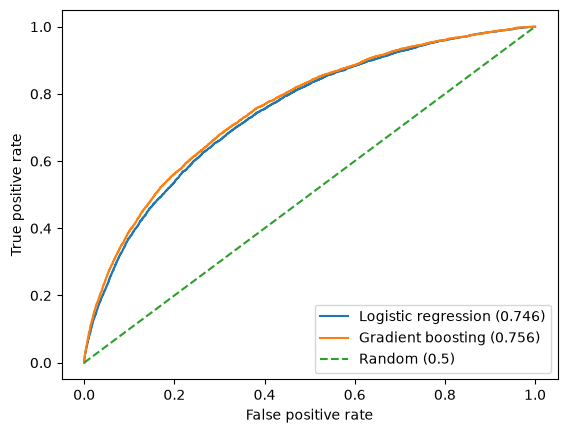

In [22]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_l, tpr_l, _ = roc_curve(y_test, proba_lr)
fpr_g, tpr_g, _ = roc_curve(y_test, proba_gb)

plt.plot(fpr_l, tpr_l, label='Logistic regression (0.746)')
plt.plot(fpr_g, tpr_g, label='Gradient boosting (0.756)')
plt.plot([0, 1], [0, 1], '--', label='Random (0.5)')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend()
plt.savefig('images/roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
import numpy as np

thr = np.quantile(proba_gb, 0.8)
flagged = proba_gb >= thr
print('default rate in flagged 20%:', y_test[flagged].mean())
print('default rate in the other 80%:', y_test[~flagged].mean())
print('share of all defaults caught:', y_test[flagged].sum() / y_test.sum())

default rate in flagged 20%: 0.21169010649540687
default rate in the other 80%: 0.04798585423356774
share of all defaults caught: 0.5244712990936556


In [24]:
from sklearn.inspection import permutation_importance

idx = X_test_g.sample(10000, random_state=42).index
imp = permutation_importance(gb, X_test_g.loc[idx], y_test.loc[idx],
                             scoring='roc_auc', n_repeats=3, random_state=42)
top = pd.Series(imp.importances_mean, index=X_test_g.columns).sort_values(ascending=False).head(10)
top

EXT_SOURCE_3           0.067149
EXT_SOURCE_2           0.044425
EXT_SOURCE_1           0.020016
AMT_GOODS_PRICE        0.012341
AMT_CREDIT             0.009525
AMT_ANNUITY            0.004090
NAME_EDUCATION_TYPE    0.003593
NAME_CONTRACT_TYPE     0.003258
ORGANIZATION_TYPE      0.003039
OWN_CAR_AGE            0.002757
dtype: float64

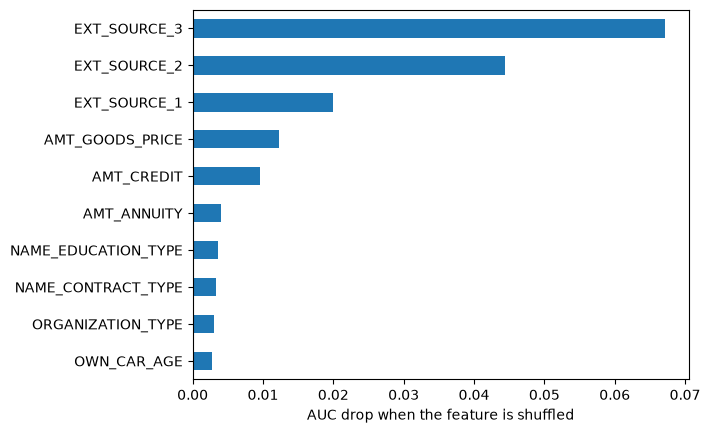

In [25]:
top.sort_values().plot(kind='barh')
plt.xlabel('AUC drop when the feature is shuffled')
plt.savefig('images/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()